# OLBM or MM-OLBM? One pipeline, two models, compared

The two block models of SELENE read the same vote matrix and answer differently:

| | OLBM, `LatentBlockModel` | MM-OLBM, `MixedMembershipBlockModel` |
| --- | --- | --- |
| A member | belongs to one group | has a membership to each group, and one role per block |
| A proposition | belongs to one block | has a membership to each block; each cell draws one |
| Fitted by | classification EM (hard labels) | exact EM over the $Q^L$ profiles (one role per block) |
| Objective | classified log-likelihood | log-likelihood plus the log-densities of Dirichlet priors |
| Shape compared by | integrated likelihood (ICL) | log-likelihood of held-out cells |
| Value | `SingleCoclustering` | `MixedCoclustering` |

This notebook runs **one pipeline** for both: load, start from the spectral arrangement,
estimate, then compare on the same footing (arrangement, co-clusters, members, held-out
votes). It does so on two synthetic collectives: one where some members are planted in
two groups at once, one where nobody is. The comparison should pick the MM-OLBM on the
first and the OLBM on the second.

The data are **synthetic** (see `data/make_data.py`). Requirements:
`pip install "civiqhub-selene[viz]"`, run from the `examples/` folder.

## Mathematical background

The formulas of this notebook use the letters of the [notation](https://selene.civiqhub.com/dev/model/notation.html)
of the mathematical model of SELENE, which derives each quantity as the code computes
it. The pages behind this notebook:

- [The latent block model](https://selene.civiqhub.com/dev/model/latent-block-model.html): one group per voter;
- [The mixed-membership model](https://selene.civiqhub.com/dev/model/mixed-membership.html): one role per block;
- [Choosing the shape](https://selene.civiqhub.com/dev/model/choosing-the-shape.html): the integrated likelihood and the log-likelihood of held-out votes;
- [Reading the results](https://selene.civiqhub.com/dev/model/reading-results.html#memberships-and-main-groups): what the memberships of each model mean.

In [1]:
import itertools

import matplotlib.pyplot as plt
import numpy as np
from loading import read_memberships, read_votes

from civiqhub_selene import viz
from civiqhub_selene.blocks import (
    LatentBlockModel,
    MixedMembershipBlockModel,
    SpectralStart,
    VoteMatrix,
)

plt.rcParams["figure.dpi"] = 90

## 1. The pipeline

Both models take the same settings for the shape, the response model and the start; the
MM-OLBM adds the concentrations of its Dirichlet priors (`voter_concentration` $\alpha$,
`item_concentration` $\beta$) and the weight of its start (`start_weight`). A model is a frozen value:
`estimate(votes, seed=...)` returns a `Result` that carries the value and its provenance.

In [2]:
def models(n_groups: int, n_blocks: int, n_starts: int = 2) -> dict:
    """The two models at the same shape, both started from the spectral arrangement."""
    return {
        "OLBM": LatentBlockModel(
            n_groups=n_groups, n_blocks=n_blocks, n_starts=n_starts, initialization=SpectralStart()
        ),
        "MM-OLBM": MixedMembershipBlockModel(
            n_groups=n_groups,
            n_blocks=n_blocks,
            n_starts=n_starts,
            max_iterations=400,
            initialization=SpectralStart(),
        ),
    }


def run_pipeline(votes: VoteMatrix, n_groups: int, n_blocks: int, seed: int = 0) -> dict:
    """Estimate both models on the same votes, with the same seed."""
    return {
        name: model.estimate(votes, seed=seed) for name, model in models(n_groups, n_blocks).items()
    }


def held_out_comparison(
    votes: VoteMatrix, n_groups: int, n_blocks: int, n_folds: int = 4, seed: int = 0
) -> None:
    """Hide each fold of the shown cells in turn, fit both models on the rest, and score
    the hidden answers by their mean log-probability. Larger is better."""
    fold = np.random.default_rng(seed).integers(0, n_folds, size=votes.shape)
    scores = {name: [] for name in models(n_groups, n_blocks)}
    for f in range(n_folds):
        held = votes.shown & (fold == f)
        training = votes.hold_out(held)
        for name, model in models(n_groups, n_blocks, n_starts=1).items():
            value = model.estimate(training, seed=seed).value
            scores[name].append(value.log_probability(votes)[held].mean())
    for name, values in scores.items():
        error = np.std(values, ddof=1) / np.sqrt(n_folds)
        print(f"{name:<8} held-out log-probability per cell: {np.mean(values):.4f} +/- {error:.4f}")


# A model is a frozen value: printing it shows every setting, which the provenance records.
for name, model in models(3, 2).items():
    print(f"{name}: {model}")
    print()

OLBM: LatentBlockModel(n_groups=3, n_blocks=2, response_model=OrdinalProbit(thresholds=None, min_spread=0.3, min_probability=1e-06, max_inner_iterations=10), n_starts=2, max_iterations=200, tolerance=1e-06, initialization=SpectralStart(encoding='states', regularization=1.0, project=True, leverage_threshold=0.0, n_init=10))

MM-OLBM: MixedMembershipBlockModel(n_groups=3, n_blocks=2, response_model=OrdinalProbit(thresholds=None, min_spread=0.3, min_probability=1e-06, max_inner_iterations=10), n_starts=2, max_iterations=400, tolerance=1e-06, initialization=SpectralStart(encoding='states', regularization=1.0, project=True, leverage_threshold=0.0, n_init=10), voter_concentration=1.2, item_concentration=1.0, start_weight=0.9)



## 2. A collective with members in two groups

`assembly`: 150 members in 3 groups, of which 30 are planted half in one group and half in
another; 20 propositions in 2 blocks, of which 4 are shared between the blocks.

In [3]:
votes = read_votes("data/assembly.votes.csv")
_, planted = read_memberships("data/assembly.voters.csv")
shared = planted.max(axis=1) < 1
results = run_pipeline(votes, n_groups=3, n_blocks=2)
single, mixed = results["OLBM"].value, results["MM-OLBM"].value
print(votes)
print()
print(single)
print()
print(mixed)

VoteMatrix(150 voters x 20 items, 1622 votes, 5 levels)
90.7% of the 3000 cells shown, 59.6% of the shown cells voted

SingleCoclustering(150 voters in 3 groups x 20 items in 2 blocks)
groups of 55, 46, 49 voters; blocks of 8, 12 items
group 0 x block 0: vote rate 0.42, typical score 0, 166 votes
group 0 x block 1: vote rate 0.42, typical score 0, 253 votes
group 1 x block 0: vote rate 0.87, typical score +2, 296 votes
group 1 x block 1: vote rate 0.53, typical score -2, 267 votes
group 2 x block 0: vote rate 0.55, typical score -2, 188 votes
group 2 x block 1: vote rate 0.84, typical score +2, 452 votes

MixedCoclustering(150 voters in 3 groups x 20 items in 2 blocks)
groups of 46, 55, 49 voters; blocks of 11, 9 items
group 0 x block 0: vote rate 0.46, typical score -2, 208.444 votes
group 0 x block 1: vote rate 0.87, typical score +2, 363.305 votes
group 1 x block 0: vote rate 0.89, typical score +2, 425.433 votes
group 1 x block 1: vote rate 0.57, typical score -2, 264.97 votes
grou

### 2.1 Do they agree on the main arrangement?

The MM-OLBM also gives a main group to each member (its largest membership) and a main
block to each proposition. The two models mostly agree. Group numbers are arbitrary, so
the members placed differently are counted after matching the groups of the two models.

In [4]:
print(f"members in the same main group:     {single.groups.agreement_with(mixed.groups):.1%}")
print(f"propositions in the same main block: {single.blocks.agreement_with(mixed.blocks):.1%}")

# Match the groups of the MM-OLBM to those of the OLBM, then list who differs.
match = max(
    itertools.permutations(range(3)),
    key=lambda order: (np.array(order)[mixed.group_index] == single.group_index).sum(),
)
differ = np.array(match)[mixed.group_index] != single.group_index
print(
    f"members placed differently: {differ.sum()}, "
    f"of which planted as shared: {(differ & shared).sum()}"
)

members in the same main group:     95.3%
propositions in the same main block: 95.0%
members placed differently: 7, of which planted as shared: 7


### 2.2 What each model says about the shared members

The OLBM also returns soft memberships, but they are a **soft reading** of its
arrangement, not a degree of membership nor a probability of error: for a member planted
in two groups, they are close to 1 for one of them. The MM-OLBM
returns **memberships**: the shared members get a larger mixedness, one minus their
largest membership. With $L = 2$ blocks and $\alpha = 1.2$, a member who keeps one role on
both blocks gets $0.15$, a member who changes role about $0.5$.

In [5]:
olbm_mixedness = 1 - single.group_memberships.max(axis=1)
print(f"{'':<24}{'OLBM':>8}{'MM-OLBM':>10}")
print(
    f"{'shared members':<24}{olbm_mixedness[shared].mean():>8.3f}"
    f"{mixed.mixedness[shared].mean():>10.3f}"
)
print(
    f"{'other members':<24}{olbm_mixedness[~shared].mean():>8.3f}"
    f"{mixed.mixedness[~shared].mean():>10.3f}"
)

                            OLBM   MM-OLBM
shared members             0.003     0.312
other members              0.001     0.170


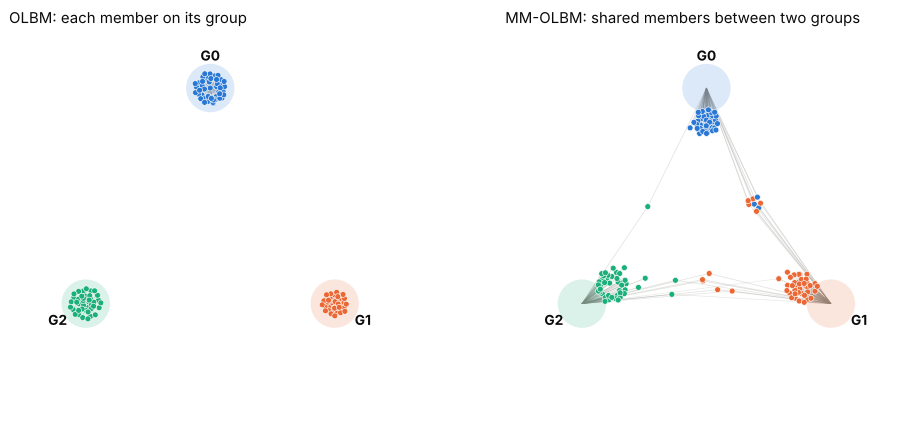

In [6]:
figure, (left, right) = plt.subplots(1, 2, figsize=(11, 4.8), layout="constrained")
viz.draw_memberships(single, ax=left)
left.set_title("OLBM: each member on its group", loc="left")
viz.draw_memberships(mixed, ax=right)
right.set_title("MM-OLBM: shared members between two groups", loc="left")
plt.show()

Only the MM-OLBM reads **roles**: the group a member follows on each block.
`role_changes(0, 1)[q, r]` counts the members who follow `q` on block 0 and `r` on
block 1; off the diagonal, a member changes coalition from one block to the other.

[[43  5  1]
 [ 3 45  4]
 [ 0  3 46]]


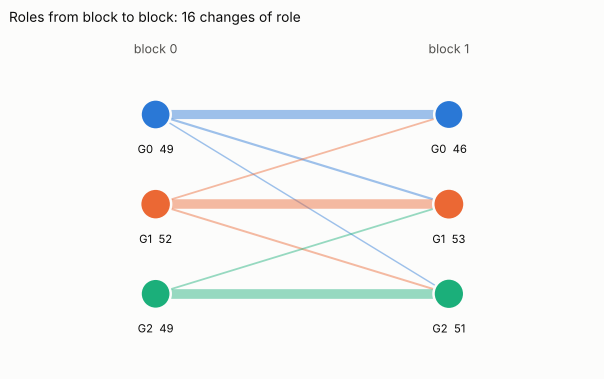

In [7]:
print(mixed.role_changes(0, 1))
viz.draw_roles(mixed)
plt.show()

### 2.3 Which model predicts the votes better?

The ICL compares shapes of the OLBM only; the two models are compared on **held-out
cells**, the criterion of the MM-OLBM note. Here the MM-OLBM predicts the hidden answers
better, by several standard errors: the shared members are real.

In [8]:
held_out_comparison(votes, n_groups=3, n_blocks=2)

OLBM     held-out log-probability per cell: -1.4000 +/- 0.0197
MM-OLBM  held-out log-probability per cell: -1.2371 +/- 0.0102


### 2.4 Side by side

The sorted matrices look alike: both models find the same blocks of agreement. The
differences hide in the rows of the shared members, which the OLBM must put in one group.

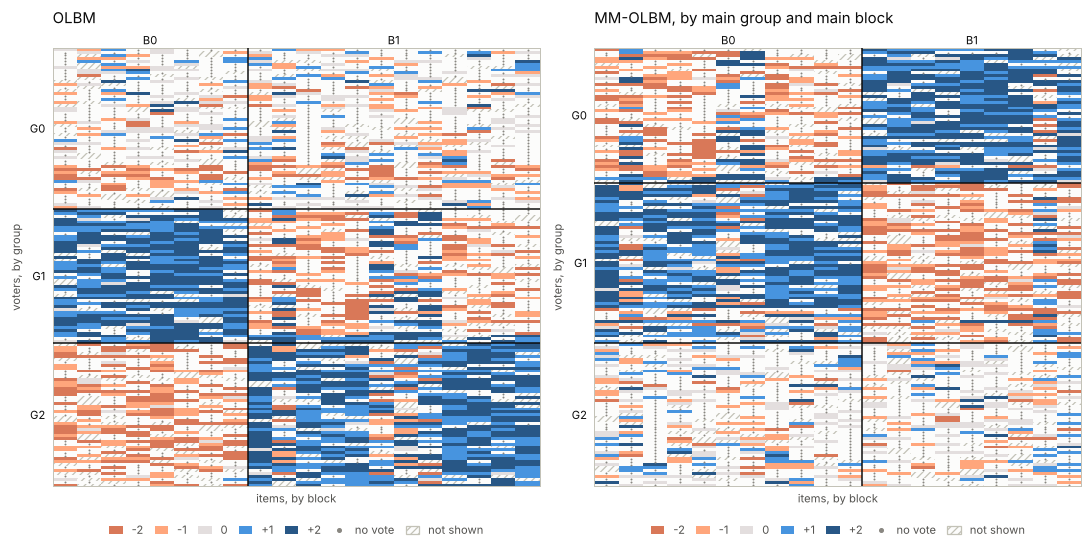

In [9]:
figure, (left, right) = plt.subplots(1, 2, figsize=(12, 6), layout="constrained")
viz.plot_vote_matrix(votes, single, ax=left)
left.set_title("OLBM", loc="left", pad=20)
viz.plot_vote_matrix(votes, mixed, ax=right)
right.set_title("MM-OLBM, by main group and main block", loc="left", pad=20)
plt.show()

## 3. A collective where nobody is shared

`consultation`: 240 members in 3 groups, 24 propositions in 3 blocks, every member planted
in a single group. Both models find the same arrangement. On held-out cells, the OLBM is
now the better one: the MM-OLBM pays for a flexibility that the data do not need (one
membership vector per member, pulled towards the interior by its pseudo-count).

In [10]:
votes = read_votes("data/consultation.votes.csv")
results = run_pipeline(votes, n_groups=3, n_blocks=3)
single, mixed = results["OLBM"].value, results["MM-OLBM"].value
print(f"members in the same main group:     {single.groups.agreement_with(mixed.groups):.1%}")
print(f"propositions in the same main block: {single.blocks.agreement_with(mixed.blocks):.1%}")
held_out_comparison(votes, n_groups=3, n_blocks=3, n_folds=3)

members in the same main group:     100.0%
propositions in the same main block: 100.0%


OLBM     held-out log-probability per cell: -1.2415 +/- 0.0051
MM-OLBM  held-out log-probability per cell: -1.2746 +/- 0.0067


## 4. Reading the comparison

- **Same main arrangement?** Compare `groups` and `blocks` with `agreement_with`. The
  MM-OLBM keeps the main structure of the OLBM when members are not shared.
- **Shared members?** Read the mixedness of the MM-OLBM as a histogram
  (`viz.plot_mixedness`) and its changes of role (`role_changes`, `viz.draw_roles`). The
  soft memberships of the OLBM are not memberships: they say how sure the model is of one
  group.
- **Which model?** Compare them on held-out cells, at the same shape. The MM-OLBM wins when
  members do change coalition from one block to the other; otherwise the OLBM is simpler
  and predicts as well or better.
- **Which shape?** The ICL grid of notebook 02 for the OLBM; for the MM-OLBM, the same
  held-out comparison over a grid of shapes. The function `select_shape` that will do both
  is not written yet.

To run this pipeline on your own votes, build the matrix with
`VoteMatrix.from_records(votes, shown=shown)` (see `loading.py`), then call
`run_pipeline(votes, n_groups, n_blocks)`. Keep real data out of the repository.